# 09 · Neural Network (Keras)

**Goal:** add the model from module 05 (gradient descent and *Intro to Deep Learning*) and compare it fairly with
the models from notebooks 04–05. The lesson's house-price network is the same kind of problem as ours: a regression
on a price.

**The course recipe, step by step:**

1. Split into **train, validation and test**. The test set stays the same 41,529 cars as every other notebook;
   20% of the training set becomes the validation set that early stopping watches.
2. **Scale the inputs**, fit on the training part only: here the same `linear_preprocessor()` as Linear Regression
   (scaled numbers plus one-hot categories), because a network, like gradient descent, needs features on one scale.
3. Build a `Sequential` model: `Input` → `Dense` hidden layers with **ReLU** → one `Dense(1, activation='linear')`
   output for a number.
4. `compile(loss='mse', optimizer=Adam(...))`, then `fit` with `validation_data`, `epochs`, `batch_size` and an
   **`EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`** callback.
5. Plot the **history** (loss vs val_loss) to check for under- or overfitting.

As in every model notebook, the network predicts `log(price)`; predictions are turned back with `exp` and scored in
dollars.

⏱️ *Runtime: about 2 minutes.*

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow start-up messages
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import keras
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

sys.path.append('../src')
from prep import (load_data, split, add_model_top, linear_preprocessor, evaluate, save_result,
                  save_params, near_twin_mask, RANDOM_STATE)

sns.set_theme(style='whitegrid')
print('Keras', keras.__version__)

df = load_data()
X_train, X_test, y_train, y_test = split(df)            # same 80/20 split as every notebook
X_train, X_test = add_model_top(X_train, X_test)

# Step 1: carve a validation set out of the training set (the test set is not touched)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
print(f'train: {len(X_fit):,} | validation: {len(X_val):,} | test: {len(X_test):,}')

Keras 3.15.1


train: 132,892 | validation: 33,223 | test: 41,529


In [2]:
# Step 2: scale and one-hot encode, fit on the training part only
pre = linear_preprocessor().fit(X_fit)
A_fit = pre.transform(X_fit).astype('float32')
A_val = pre.transform(X_val).astype('float32')
A_test = pre.transform(X_test).astype('float32')
y_fit_log, y_val_log = np.log(y_fit.values), np.log(y_val.values)
print('inputs per car:', A_fit.shape[1])

inputs per car: 430


## 1. Two networks, compared on the validation set

- **Network A, the lesson's network:** three hidden layers of 30, 20 and 15 neurons, `Adam(learning_rate=0.01)`,
  batch size 64.
- **Network B, wider:** 256, 128 and 64 neurons, the default `Adam` learning rate (0.001), batch size 256. Our data
  has 439 inputs and about 133,000 training rows, against 8 inputs and about 13,000 rows in the lesson, so a wider
  network has more room to learn.

Both stop early when the validation loss has not improved for 5 epochs, and keep their best weights.
`keras.utils.set_random_seed` makes the runs repeatable.

In [3]:
def build(layers, learning_rate):
    keras.utils.set_random_seed(RANDOM_STATE)
    model = Sequential([Input(shape=(A_fit.shape[1],))] +
                       [Dense(n, activation='relu') for n in layers] +
                       [Dense(1, activation='linear')])
    model.compile(loss='mse', optimizer=Adam(learning_rate=learning_rate), metrics=['mae'])
    return model

settings = {
    'A: 30-20-15 (lesson)': dict(layers=(30, 20, 15), learning_rate=0.01, batch_size=64),
    'B: 256-128-64': dict(layers=(256, 128, 64), learning_rate=0.001, batch_size=256),
}
runs = {}
for name, s in settings.items():
    model = build(s['layers'], s['learning_rate'])
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    t = time.time()
    history = model.fit(A_fit, y_fit_log, validation_data=(A_val, y_val_log), epochs=100,
                        batch_size=s['batch_size'], callbacks=[es], verbose=0)
    val_pred = np.exp(model.predict(A_val, verbose=0).ravel())
    runs[name] = {'model': model, 'history': pd.DataFrame(history.history),
                  'epochs run': len(history.history['loss']),
                  'best epoch': int(np.argmin(history.history['val_loss'])) + 1,
                  'seconds': round(time.time() - t),
                  'validation MAE ($)': round(np.mean(np.abs(val_pred - y_val.values)))}
    print(f"{name}: {runs[name]['epochs run']} epochs, {runs[name]['seconds']} s, "
          f"validation MAE ${runs[name]['validation MAE ($)']:,}")
pd.DataFrame({n: {k: v for k, v in r.items() if k not in ('model', 'history')} for n, r in runs.items()}).T

A: 30-20-15 (lesson): 20 epochs, 63 s, validation MAE $3,439


B: 256-128-64: 12 epochs, 26 s, validation MAE $3,693


,epochs run,best epoch,seconds,validation MAE ($)
A: 30-20-15 (lesson),20,15,63,3439
B: 256-128-64,12,7,26,3693


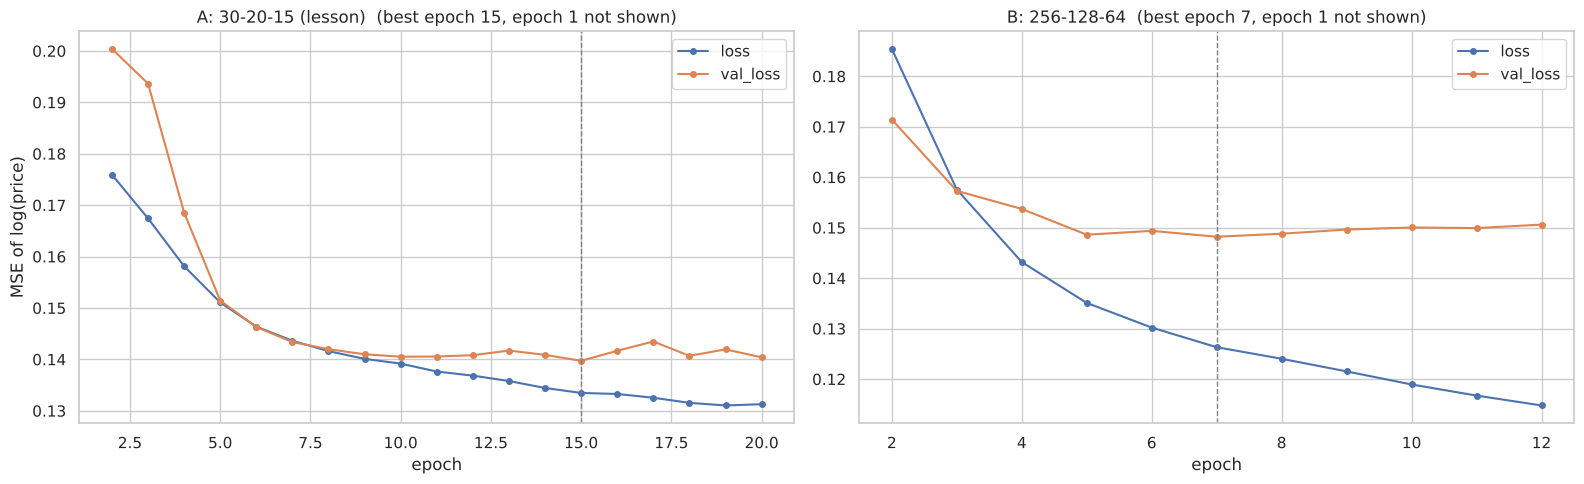

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, r) in zip(axes, runs.items()):
    h = r['history'][['loss', 'val_loss']]
    h.index = h.index + 1                       # epochs counted from 1
    h.iloc[1:].plot(ax=ax, marker='o', markersize=4)   # epoch 1 starts far higher and would flatten the plot
    ax.axvline(r['best epoch'], color='grey', linestyle='--', linewidth=1)
    ax.set_title(f'{name}  (best epoch {r["best epoch"]}, epoch 1 not shown)')
    ax.set_xlabel('epoch')
axes[0].set_ylabel('MSE of log(price)')
plt.tight_layout()
plt.show()

**Reading the loss curves:**

- **Network A (the lesson's):** training and validation loss fall together until about epoch 7. After that the
  validation loss levels off near 0.14 while the training loss keeps falling slowly. The best epoch is 15, and early
  stopping ended the run at epoch 20.
- **Network B (wider):** the validation loss stops improving after about epoch 5, while the training loss keeps
  dropping (0.126 at epoch 7, 0.115 at epoch 12). That gap is **overfitting**: the bigger network starts to memorise
  the training cars. Its best validation MAE (\$3,693) is worse than A's (\$3,439).
- More neurons are not better here. Without extra tools against overfitting, the small network generalises better.

## 2. The chosen network on the test set

The network with the lower validation MAE is kept and scored **once** on the test set, like the other models.

In [5]:
best_name = min(runs, key=lambda n: runs[n]['validation MAE ($)'])
nn = runs[best_name]['model']
print('chosen:', best_name)
for layer in nn.layers:          # a plain-text version of model.summary()
    print(f'{layer.name:8s} {layer.units:4d} neurons  {layer.count_params():6,d} weights')
print(f'total: {nn.count_params():,} weights')

test_pred = np.exp(nn.predict(A_test, verbose=0).ravel())
row = evaluate('Neural Network', y_test.values, test_pred)
results = save_result(row)
save_params('Neural Network', {'layers': '-'.join(map(str, settings[best_name]['layers'])),
                               'learning_rate': settings[best_name]['learning_rate'],
                               'batch_size': settings[best_name]['batch_size'],
                               'epochs': runs[best_name]['best epoch']})
results.sort_values('mae')

chosen: A: 30-20-15 (lesson)
dense      30 neurons  12,930 weights
dense_1    20 neurons     620 weights
dense_2    15 neurons     315 weights
dense_3     1 neurons      16 weights
total: 13,881 weights


,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
7,Random Forest,log(price),3231.402,6184.166,0.804,26.969,1745.899
6,Gradient Boosting,log(price),3303.451,6348.464,0.793,27.570,1760.566
8,Neural Network,log(price),3559.053,6818.972,0.762,29.703,1843.469
5,ElasticNet,log(price),4149.163,7767.575,0.690,34.628,2151.550
4,Ridge,log(price),4149.765,7862.822,0.683,34.633,2150.480
3,Linear Regression,log(price),4150.916,7886.378,0.681,34.643,2150.929
2,Lasso,log(price),4151.412,7829.515,0.686,34.647,2150.222
1,Decision Tree,log(price),4195.589,7433.051,0.717,35.016,2354.399
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.000


In [6]:
# Same checks as notebooks 06-07: honest error on cars without a near twin, and share within 20%
preds = pd.read_csv('../results/test_predictions.csv')
assert (preds['price'].values == y_test.values).all()
preds['Neural Network'] = test_pred.round(0)
preds.to_csv('../results/test_predictions.csv', index=False)

twin = near_twin_mask(X_train, X_test)
rows = []
for name in ['Neural Network', 'Random Forest', 'Gradient Boosting']:
    err = (preds[name] - preds['price']).abs()
    rows.append({'model': name, 'MAE all': err.mean(), 'MAE no near twin': err[~twin].mean(),
                 'within 20% (%)': (err / preds['price'] <= 0.2).mean() * 100,
                 'median % error': (err / preds['price']).median() * 100})
pd.DataFrame(rows).set_index('model').round(1)

,MAE all,MAE no near twin,within 20% (%),median % error
model,,,,
Neural Network,3559.1,3830.4,56.9,17.1
Random Forest,3231.4,3524.3,59.5,15.8
Gradient Boosting,3303.5,3546.2,59.2,16.0


In [7]:
# Where does the network differ from the forest? Error by price band
bands = pd.cut(preds['price'], [0, 5_000, 10_000, 20_000, 35_000, 150_000],
               labels=['< $5k', '$5-10k', '$10-20k', '$20-35k', '> $35k'])
band_table = pd.DataFrame({name: (preds[name] - preds['price']).abs().groupby(bands, observed=True).mean()
                           for name in ['Neural Network', 'Random Forest']}).round(0)
band_table['difference'] = band_table['Neural Network'] - band_table['Random Forest']
band_table

,Neural Network,Random Forest,difference
price,,,
< $5k,1707.0,1796.0,-89.0
$5-10k,1642.0,1655.0,-13.0
$10-20k,2849.0,2686.0,163.0
$20-35k,5047.0,4413.0,634.0
> $35k,12396.0,10273.0,2123.0


## Summary

| Model | Test MAE | R² | MAE on new listings (no near twin) | Within 20% |
| --- | --- | --- | --- | --- |
| Random Forest | \$3,231 | 0.804 | \$3,524 | 59.5% |
| Gradient Boosting | \$3,303 | 0.793 | \$3,546 | 59.2% |
| **Neural Network** | **\$3,559** | **0.762** | **\$3,830** | **56.9%** |
| ElasticNet (best linear) | \$4,149 | 0.690 | – | – |

- **The network ranks third of the nine models:** 14% better than Linear Regression (\$4,151), but 10% behind the
  Random Forest. On new listings it is \$306 behind.
- **It is better on the cheapest cars:** under \$5,000 its error is \$1,707 against \$1,796 for the forest, and level
  for \$5–10k. Above \$10,000 it falls behind, by \$2,123 above \$35,000. Expensive cars are rare combinations
  (trims, trucks, diesels) that the forest's deep trees can single out, while a 30-neuron network smooths them over.
- **Speed:** the chosen network trains in about one minute on a CPU, about the same as the forest.

**Decision:** Random Forest stays the main model. The network confirms the result from a completely different
method. Its edge on cheap cars, exactly where the forest is weakest, suggests that averaging the two could help:
an idea for later.